In [2]:
import numpy as np
import matplotlib.pyplot as plt
import batman
import emcee
import corner

# load K2 data
data = np.loadtxt(
    "../data/apjladf06ft3_mrt.txt",
    skiprows=15
)

t = data[:, 0] + 2454833 #offset to BJD
flux = data[:, 2]

# published mid-transit time from Venner et al. (2026)
t0_published = 2458055.0969

mask = np.abs(t - t0_published) < 0.8 # keep only data points within +/- 0.8 days (19.2h) around the transit

t_transit = t[mask]
flux_transit = flux[mask]

In [3]:
# Gravitational constant in SI units
G = 6.67430e-11


def a_over_rstar(period, rho_star):
    """
    Calculate a/R_star from the orbital period and stellar density.

    period   : orbital period in days
    rho_star : stellar density in g/cm^3
    """

    # convert period from days to seconds
    P_seconds = period * 24 * 60 * 60

    # convert density from g/cm^3 to kg/m^3
    rho_si = rho_star * 1000

    # Kepler's third law in terms of stellar density
    a_Rstar = (G * rho_si * P_seconds**2 / (3 * np.pi))**(1/3)

    return a_Rstar

In [4]:
def transit_model(theta):
    """
    circular transit model for a given set of parameters
    theta = (period, b, rp, t0, rho_star)
    """

    period, b, rp, t0, rho_star = theta

    # calculate a/R_star from P and the stellar density
    a_Rstar = a_over_rstar(period, rho_star)

    # for a circular orbit: b = (a/R_star) * cos(i)
    cos_i = b / a_Rstar

    # some parameter combinations are geometrically impossible
    if cos_i < 0 or cos_i > 1:
        return None

    inclination = np.degrees(np.arccos(cos_i))

    params = batman.TransitParams()

    params.t0 = t0
    params.per = period
    params.rp = rp
    params.a = a_Rstar
    params.inc = inclination

    # for now we reproduce the circular-orbit assumption of the paper
    params.ecc = 0.0
    params.w = 90.0

    # keep limb darkening fixed for the first model
    params.u = [0.56, 0.10]
    params.limb_dark = "quadratic"

    model = batman.TransitModel(
        params,
        t_transit,
        supersample_factor=10,
        exp_time=29.4 / (24 * 60)
    )

    return model.light_curve(params)

In [5]:
# Estimate the scatter from the out-of-transit data.
# The transit lasts about 10 h, so points > 0.3 d from t0
# should safely be outside the transit.

out_of_transit = np.abs(t_transit - t0_published) > 0.3

sigma_flux = np.std(flux_transit[out_of_transit])

print("Estimated flux uncertainty:", sigma_flux)

Estimated flux uncertainty: 3.2270422821042794e-05


In [6]:
def log_likelihood(theta):
    """
    Gaussian log-likelihood:
    compares the observed flux to the transit model.
    """

    model_flux = transit_model(theta)

    # If the parameter combination is impossible,
    # give it zero probability
    if model_flux is None:
        return -np.inf

    residuals = flux_transit - model_flux

    log_likelihood = -0.5 * np.sum(
        residuals**2 / sigma_flux**2
        + np.log(2 * np.pi * sigma_flux**2)
    )

    return log_likelihood

In [7]:
def log_prior(theta):
    """
    Priors for the first circular model.

    These are simple test priors for now and will later be replaced
    by the priors we actually want to investigate.
    """

    period, b, rp, t0, rho_star = theta

    # Period must be positive and reasonably long because
    # only one transit was seen during the K2 observing window
    if not 100 < period < 1000:
        return -np.inf

    # Impact parameter:
    # b = 0 means a central transit
    if not 0 <= b < 1:
        return -np.inf

    # Planet/star radius ratio
    if not 0.005 < rp < 0.03:
        return -np.inf

    # Mid-transit time should stay close to the observed event
    if not t0_published - 0.1 < t0 < t0_published + 0.1:
        return -np.inf

    # Broad range for the stellar density
    if not 1.0 < rho_star < 5.0:
        return -np.inf

    # Inside these ranges we currently use flat priors
    return 0.0

In [8]:
def log_probability(theta):
    """
    Log posterior = log prior + log likelihood.
    """

    lp = log_prior(theta)

    # If the prior says that this parameter combination is impossible,
    # we do not need to calculate the likelihood
    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood(theta)

In [9]:
theta_test = (
    355.0,          # period [days]
    0.0,            # impact parameter
    0.01368,        # Rp/Rstar
    2458055.0969,   # t0
    2.90            # stellar density [g/cm^3]
)

print("log prior:", log_prior(theta_test))
print("log likelihood:", log_likelihood(theta_test))
print("log probability:", log_probability(theta_test))

log prior: 0.0
log likelihood: 595.9642961361618
log probability: 595.9642961361618


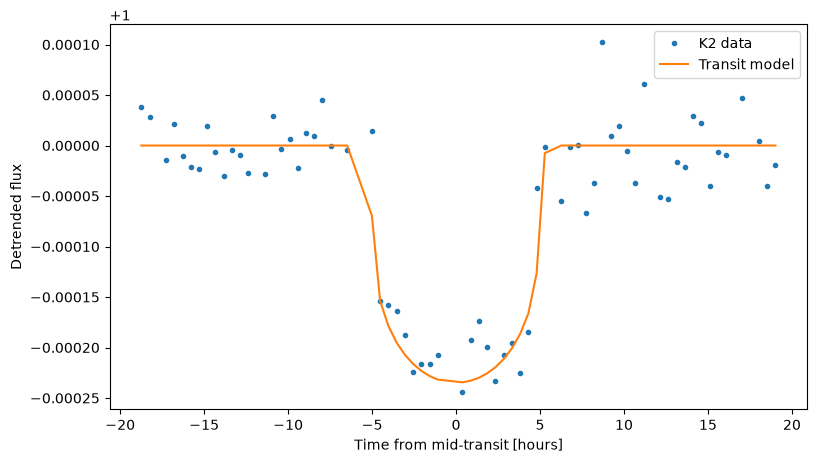

In [10]:
model_test = transit_model(theta_test)

plt.figure(figsize=(9, 5))

plt.plot(
    (t_transit - t0_published) * 24,
    flux_transit,
    ".",
    label="K2 data"
)

plt.plot(
    (t_transit - t0_published) * 24,
    model_test,
    label="Transit model"
)

plt.xlabel("Time from mid-transit [hours]")
plt.ylabel("Detrended flux")
plt.legend()
plt.show()

In [11]:
# Parameters in theta:
# period, impact parameter b, Rp/Rstar, mid-transit time, stellar density

ndim = 5
nwalkers = 40

# Starting point close to the published solution.
# We don't start all walkers at exactly the same point,
# otherwise they cannot properly explore the parameter space.
initial = np.array([
    355.0,          # period [days]
    0.3,            # impact parameter
    0.01368,        # Rp/Rstar
    t0_published,   # mid-transit time
    2.90            # stellar density [g/cm^3]
])

# How much the initial walkers are spread around the starting point
spread = np.array([
    20.0,      # period
    0.10,      # b
    0.0005,    # Rp/Rstar
    0.005,     # t0
    0.10       # rho_star
])

rng = np.random.default_rng(42)

pos = initial + spread * rng.normal(
    size=(nwalkers, ndim)
)

In [13]:
#run mcmc

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_probability
)

sampler.run_mcmc(
    pos,
    5000,
    progress=True
)

You must install the tqdm library to use progress indicators with emcee


State([[5.96328324e+02 5.05400019e-01 1.39923152e-02 2.45805510e+06
  3.82117686e+00]
 [5.00374273e+02 7.63691541e-01 1.53143592e-02 2.45805510e+06
  1.24580301e+00]
 [3.34060516e+02 4.53000880e-01 1.42016505e-02 2.45805510e+06
  2.34970181e+00]
 [9.94497417e+02 8.68709462e-01 1.57998976e-02 2.45805510e+06
  1.19511186e+00]
 [6.33859156e+02 8.00945688e-01 1.48267461e-02 2.45805510e+06
  1.23326308e+00]
 [5.42770866e+02 2.60027631e-01 1.42903648e-02 2.45805510e+06
  4.64125522e+00]
 [6.15945183e+02 6.07802915e-01 1.45145868e-02 2.45805509e+06
  2.86244915e+00]
 [6.25780657e+02 4.34307058e-01 1.38758478e-02 2.45805510e+06
  4.25278738e+00]
 [9.45698997e+02 5.54383292e-01 1.39462646e-02 2.45805510e+06
  4.99355563e+00]
 [5.36806488e+02 1.04696787e-01 1.35589580e-02 2.45805510e+06
  4.83785875e+00]
 [4.05373995e+02 1.43883655e-01 1.40817256e-02 2.45805510e+06
  3.94111517e+00]
 [7.58597449e+02 6.05628858e-01 1.48553650e-02 2.45805509e+06
  3.74375846e+00]
 [2.15384309e+02 5.98571094e-01 1.

In [14]:
acceptance = sampler.acceptance_fraction

print("Mean acceptance fraction:")
print(np.mean(acceptance))

Mean acceptance fraction:
0.33311


In [ ]:


samples = sampler.get_chain()

labels = [
    "Period [d]",
    "b",
    "Rp/Rstar",
    "t0 [BJD]",
    "rho_star"
]

fig, axes = plt.subplots(
    ndim,
    figsize=(10, 10),
    sharex=True
)

for i in range(ndim):

    axes[i].plot(
        samples[:, :, i],
        alpha=0.3
    )

    axes[i].set_ylabel(labels[i])

axes[-1].set_xlabel("MCMC step")

plt.tight_layout()
plt.show()